# Plot contrast series from HDF5

Reads the HDF5 file written by `organize_contrastseries_to_hdf5` and plots the mean response to each contrast with `plot_all_contrasts_overlay_compactstyle_from_csvs` (the function from the plotting notebook, unchanged apart from the HyLight2 name and color).

- **Mean and SEM** are calculated across all individual traces (neurons) of a sensor and contrast, pooled over flies. Each trace is first resampled to `target_hz` by linear interpolation; with `apply_smoothing=True` the mean and SEM are then smoothed with a moving average of `wid` samples.
- **Two plot cells:** contrasts below 0.5 (darker than the background, 300 ms dark flash) and contrasts above 0.5 (brighter than the background, 300 ms light flash). Each cell plots HyLight2 and jRGECO1a.

In [1]:
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

## 1. Settings

In [9]:
H5_FILE = Path("your/path/here/contrastseries_hylight2.h5")

COMPARTMENT = "m9"          # None = all compartments in the file
HYLIGHT_SENSOR = "hylight2"
CA_SENSOR = "ca"

## 2. Functions
Run these cells; no changes needed.

In [10]:
def read_contrast_series_hdf5(h5_file, sensor=None, compartment=None):
    """
    Records from the HDF5 file, optionally for one sensor and/or compartment.
    Each record is one recording (fly, compartment, sensor, contrast) with its
    traces [neurons x time points], in the form the plotting functions take.
    Rows that are entirely NaN are dropped, as in read_contrast_series_csvs.
    """
    records = []
    with h5py.File(h5_file, "r") as f:
        for fly_id, fly in f.items():
            for comp_name, comp in fly.items():
                if compartment is not None and comp_name != compartment:
                    continue
                
                for sensor_name, sgrp in comp.items():
                    if sensor is not None and sensor_name != sensor:
                        continue
                    for dset in sgrp.values():
                        a = dset.attrs
                        traces = np.asarray(dset[()], dtype=float)
                        if traces.ndim == 1:
                            traces = traces[None, :]
                        traces = traces[np.any(np.isfinite(traces), axis=1)]
                        freq = float(a["imaging_frequency"])
                        if traces.shape[0] == 0 or not np.isfinite(freq) or freq <= 0:
                            print(f"Skipping /{fly_id}/{comp_name}/{sensor_name}/{dset.name.split('/')[-1]}: "
                                  "no finite traces or no imaging frequency")
                            continue
                        records.append({
                            "fly_id": fly_id,
                            "condition": fly.attrs.get("condition", ""),
                            "date": a["date"],
                            "series_number": a["series"],
                            "sensor": sensor_name,
                            "layer": comp_name,
                            "n_traces": traces.shape[0],
                            "contrast_label": a["contrast_label"],
                            "contrast": float(a["contrast"]),
                            "frequency": freq,
                            "duration": traces.shape[1] / freq,
                            "traces": traces,
                        })
    return records

In [11]:
def smooth(x, axis=0, wid=3):
    # this is way faster than convolve
    if wid < 2:
        return x

    x = np.asarray(x, dtype=float)

    cumsum_vec = np.cumsum(np.insert(x, 0, 0, axis=axis), axis=axis)
    ma_vec = (cumsum_vec[wid:] - cumsum_vec[:-wid]) / wid

    y = x.copy()
    start_ind = int(np.floor((wid - 1) / 2))
    end_ind = wid - 1 - start_ind

    if end_ind == 0:
        y[start_ind:] = ma_vec
    else:
        y[start_ind:-end_ind] = ma_vec

    return y


def resample_trace(trace, source_freq, target_time):
    """
    Resample one trace onto target_time using linear interpolation.
    """
    trace = np.asarray(trace, dtype=float)
    source_time = np.arange(len(trace)) / float(source_freq)

    good = np.isfinite(trace)

    if good.sum() < 2:
        return np.full_like(target_time, np.nan, dtype=float)

    y = np.full_like(target_time, np.nan, dtype=float)

    valid_target = (
        (target_time >= source_time[good].min()) &
        (target_time <= source_time[good].max())
    )

    y[valid_target] = np.interp(
        target_time[valid_target],
        source_time[good],
        trace[good]
    )

    return y


def collect_contrast_traces(
    records,
    sensor,
    contrast,
    target_hz=50,
    xlim=(0, 20)
):
    """
    Collect all individual traces matching one sensor and one contrast level.

    Returns
    -------
    traces : np.ndarray
        Shape = n_individual_traces x n_timepoints

    target_time : np.ndarray
        Time vector in seconds.

    Notes
    -----
    This function does NOT average within imaging series.
    Each row from each CSV is resampled separately and then stacked.
    """

    group_records = [
        rec for rec in records
        if rec["sensor"] == sensor and np.isclose(rec["contrast"], contrast)
    ]

    if len(group_records) == 0:
        return None, None

    max_time = min(
        xlim[1],
        min(rec["duration"] for rec in group_records)
    )

    target_time = np.arange(xlim[0], max_time, 1 / target_hz)

    traces = []

    for rec in group_records:

        # Current format: rows are individual traces / ROIs
        if "traces" in rec:
            trace_arr = np.asarray(rec["traces"], dtype=float)

            if trace_arr.ndim == 1:
                trace_arr = trace_arr[None, :]

            for one_trace in trace_arr:
                resampled = resample_trace(
                    one_trace,
                    rec["frequency"],
                    target_time
                )
                traces.append(resampled)

        # Backward compatibility with old records
        elif "trace" in rec:
            resampled = resample_trace(
                rec["trace"],
                rec["frequency"],
                target_time
            )
            traces.append(resampled)

    if len(traces) == 0:
        return None, None

    traces = np.vstack(traces)

    return traces, target_time


def mean_sem_from_traces(traces):
    """
    Compute mean and SEM across individual traces.
    Handles all-NaN timepoints safely.

    Input shape:
        n_individual_traces x n_timepoints
    """

    traces = np.asarray(traces, dtype=float)

    n = np.sum(np.isfinite(traces), axis=0)

    mean_trace = np.full(traces.shape[1], np.nan)
    sem_trace = np.full(traces.shape[1], np.nan)

    valid = n > 0

    mean_trace[valid] = np.nansum(traces[:, valid], axis=0) / n[valid]

    if traces.shape[0] > 1:
        sem_trace[valid] = np.nanstd(traces[:, valid], axis=0) / np.sqrt(n[valid])
    else:
        sem_trace[valid] = 0

    return mean_trace, sem_trace

In [12]:
def _normalize_stim_type(stim_type: str) -> str:
    s = str(stim_type).lower().strip()
    s = s.replace(" ", "").replace("_", "").replace("-", "")

    aliases = {
        "20xflicker": "20xflicker",
        "300msdark": "300ms-dark",
        "300mslight": "300ms-light",
    }

    if s not in aliases:
        raise ValueError(
            f"Unknown stim_type '{stim_type}'. "
            f"Supported values: '20xflicker', '300msdark', '300mslight'"
        )

    return aliases[s]


def _stimulus_segments(stim_type: str, stim_start: float = 1.0):
    stim_type = _normalize_stim_type(stim_type)

    if stim_type == "20xflicker":
        total_duration = 4.0
        half_phase = 0.25

        segments = []
        for i in range(int(round(total_duration / half_phase))):
            seg_start = stim_start + i * half_phase
            seg_end = seg_start + half_phase
            seg_color = "white" if i % 2 == 0 else "black"
            segments.append((seg_start, seg_end, seg_color))

        return segments, stim_start + total_duration

    if stim_type == "300ms-dark":
        return [(stim_start, stim_start + 0.3, "black")], stim_start + 0.3

    if stim_type == "300ms-light":
        return [(stim_start, stim_start + 0.3, "white")], stim_start + 0.3


def _style_compact_axis(
    ax,
    tmin,
    tmax,
    ylim,
    stim_type,
    stim_start=1.0,
    add_stim_background=True,
    stim_background_color="0.88",
    stim_background_alpha=1.0,
    background_bar_color="0.8",
):
    ax.set_xlim(tmin, tmax)
    ax.set_ylim(*ylim)

    for side in ("top", "right", "left", "bottom"):
        ax.spines[side].set_visible(False)

    ax.set_xticks([])
    ax.set_yticks([])
    ax.tick_params(bottom=False, left=False)
    ax.grid(False)

    segments, stim_end = _stimulus_segments(
        stim_type,
        stim_start=stim_start
    )

    # gray stimulus-duration window behind trace
    if add_stim_background:
        ax.axvspan(
            stim_start,
            stim_end,
            color=stim_background_color,
            alpha=stim_background_alpha,
            lw=0,
            zorder=0
        )

    # top stimulus bar
    bar_ax = ax.inset_axes(
        [0, 1.03, 1, 0.10],
        transform=ax.transAxes,
        clip_on=False
    )

    bar_ax.set_xlim(tmin, tmax)
    bar_ax.set_ylim(0, 1)

    # full background bar
    bar_ax.add_patch(Rectangle(
        (tmin, 0),
        tmax - tmin,
        1,
        facecolor=background_bar_color,
        edgecolor="black",
        linewidth=0.9
    ))

    # stimulus segment
    for seg_start, seg_end, seg_color in segments:
        bar_ax.add_patch(Rectangle(
            (seg_start, 0),
            seg_end - seg_start,
            1,
            facecolor=seg_color,
            edgecolor="none",
            linewidth=0
        ))

    # outer border
    bar_ax.add_patch(Rectangle(
        (tmin, 0),
        tmax - tmin,
        1,
        facecolor="none",
        edgecolor="black",
        linewidth=0.9
    ))

    bar_ax.axis("off")


def _draw_footer_scale_bar(
    fig,
    ax,
    foot,
    t_anchor_data,
    df_over_f_scale=0.10,
    time_scale=0.5,
    x0=-0.03,
    y0=1.4,
    line_width=1.0,
    fontsize=9,
    df_label_prefix="",
):
    foot.set_axis_off()
    foot.set_xlim(0, 1)
    foot.set_ylim(0, 1)
    foot.set_autoscale_on(False)

    fig.canvas.draw()

    to_disp = ax.transData.transform
    from_disp_footer = foot.transAxes.inverted().transform

    # horizontal length
    p0x = to_disp((t_anchor_data, 0.0))
    p1x = to_disp((t_anchor_data + time_scale, 0.0))
    q0x = from_disp_footer(p0x)
    q1x = from_disp_footer(p1x)
    time_frac = q1x[0] - q0x[0]

    # vertical length
    p0y = to_disp((t_anchor_data, 0.0))
    p1y = to_disp((t_anchor_data, df_over_f_scale))
    q0y = from_disp_footer(p0y)
    q1y = from_disp_footer(p1y)
    df_frac = q1y[1] - q0y[1]

    foot.add_line(Line2D(
        [x0, x0],
        [y0, y0 + df_frac],
        transform=foot.transAxes,
        lw=line_width,
        color="black",
        solid_capstyle="butt",
        clip_on=False
    ))

    foot.add_line(Line2D(
        [x0, x0 + time_frac],
        [y0, y0],
        transform=foot.transAxes,
        lw=line_width,
        color="black",
        solid_capstyle="butt",
        clip_on=False
    ))

    foot.text(
        x0 - 0.035,
        y0 + df_frac / 2,
        f"{df_label_prefix}{int(round(df_over_f_scale * 100))}%\nΔF/F",
        transform=foot.transAxes,
        ha="right",
        va="bottom",
        fontsize=fontsize
    )

    foot.text(
        x0 + time_frac / 2,
        y0 - 0.20,
        f"{time_scale} s",
        transform=foot.transAxes,
        ha="center",
        va="top",
        fontsize=fontsize
    )

In [13]:
def get_sensor_color(sensor, colors=None):
    default_colors = {
        "hylight": "#009E73",
        "hylight2": "#009E73",
        "ca": "#D55E00",
        "atp": "#0072B2",
        "hy800": "#CC79A7",
        "iachsnfr2": "#440154",
    }

    if colors is not None and sensor in colors:
        return colors[sensor]

    return default_colors.get(sensor, "black")


def get_sensor_label(sensor):
    sensor_labels = {
        "hylight": "HyLight",
        "hylight2": "HyLight2",
        "ca": "Ca",
        "atp": "ATP",
        "hy800": "Hy800",
        "iachsnfr2": "iAChSnFR2",
    }

    return sensor_labels.get(sensor, sensor)

In [14]:
def plot_all_contrasts_overlay_compactstyle_from_csvs(
    records,
    sensor,
    contrasts_to_plot=None,   # e.g. [-1.0, -0.5, 0.5, 1.0]
    figsize=(2.6, 3.6),
    dpi=300,
    target_hz=50,
    stim_type="300msdark",   # or "300mslight"
    stim_start=1.0,
    xlim=(0, 20),
    ylim=(-0.05, 0.20),
    df_over_f_scale=0.10,
    time_scale=0.5,
    line_width=1.6,
    sem_alpha=0.18,
    show_sem=True,
    apply_smoothing=False,
    wid=3,
    add_stim_background=True,
    stim_background_color="0.88",
    stim_background_alpha=1.0,
    cmap="viridis",
    contrast_colors=None,
    show_legend=True,
    legend_fs=7,
    title=None,
    save_path=None,
    contrast_match_tolerance=1e-8,
):
    """
    Plot selected contrast levels overlaid for one sensor.

    Each line:
        Mean across all individual traces (neurons) for one contrast.

    Shaded region:
        SEM across individual traces (neurons).

    Parameters
    ----------
    records : list of dict
        Records produced by read_contrast_series_hdf5().

    sensor : str
        Sensor to plot.

    contrasts_to_plot : sequence of float or None
        Contrasts to include in the plot.

        Examples
        --------
        contrasts_to_plot=[-1.0, -0.5, 0.5, 1.0]
        contrasts_to_plot=[0.1, 0.25, 0.5]

        The order in this list determines the plotting and legend order.

        If None, all contrasts available for the selected sensor are plotted
        in ascending order.

    contrast_match_tolerance : float
        Absolute tolerance used when matching requested contrasts to the
        contrast values stored in records. This helps avoid floating-point
        matching problems.
    """

    import numpy as np
    import matplotlib.pyplot as plt
    import matplotlib.gridspec as gridspec
    from pathlib import Path

    # ============================================================
    # Find all contrasts available for this sensor
    # ============================================================
    available_contrasts = sorted({
        float(rec["contrast"])
        for rec in records
        if (
            rec.get("sensor") == sensor
            and rec.get("contrast") is not None
            and np.isfinite(float(rec["contrast"]))
        )
    })

    if len(available_contrasts) == 0:
        print(f"No data found for sensor: {sensor}")
        return None

    # ============================================================
    # Select contrasts
    # ============================================================
    if contrasts_to_plot is None:
        contrasts = available_contrasts

    else:
        if np.isscalar(contrasts_to_plot):
            contrasts_to_plot = [contrasts_to_plot]

        requested_contrasts = [
            float(contrast)
            for contrast in contrasts_to_plot
        ]

        contrasts = []
        missing_contrasts = []

        for requested in requested_contrasts:

            matches = [
                available
                for available in available_contrasts
                if np.isclose(
                    available,
                    requested,
                    rtol=0,
                    atol=contrast_match_tolerance,
                )
            ]

            if len(matches) == 0:
                missing_contrasts.append(requested)
                continue

            matched_contrast = matches[0]

            # Avoid plotting a contrast twice if it was repeated in the list.
            if matched_contrast not in contrasts:
                contrasts.append(matched_contrast)

        if missing_contrasts:
            print(
                f"Requested contrasts not found for sensor '{sensor}': "
                f"{missing_contrasts}"
            )
            print(
                f"Available contrasts: {available_contrasts}"
            )

    if len(contrasts) == 0:
        print(
            f"None of the requested contrasts were found for sensor: "
            f"{sensor}"
        )
        return None

    # ============================================================
    # Create figure
    # ============================================================
    fig = plt.figure(
        figsize=figsize,
        dpi=dpi,
    )

    gs = gridspec.GridSpec(
        nrows=2,
        ncols=1,
        height_ratios=[12, 3],
        hspace=0.30,
    )

    ax = fig.add_subplot(gs[0, 0])
    foot = fig.add_subplot(gs[1, 0])

    # Color map spans only the contrasts actually being plotted.
    cmap_obj = plt.colormaps.get_cmap(cmap).resampled(
        max(len(contrasts), 1)
    )

    plotted_anything = False

    # ============================================================
    # Plot each selected contrast
    # ============================================================
    for i, contrast in enumerate(contrasts):

        traces, time = collect_contrast_traces(
            records,
            sensor=sensor,
            contrast=contrast,
            target_hz=target_hz,
            xlim=xlim,
        )

        if traces is None:
            print(
                f"No traces for sensor '{sensor}', "
                f"contrast {contrast:g}"
            )
            continue

        mean_trace, sem_trace = mean_sem_from_traces(traces)

        if apply_smoothing:
            mean_plot = smooth(
                mean_trace,
                wid=wid,
            )
            sem_plot = smooth(
                sem_trace,
                wid=wid,
            )
        else:
            mean_plot = mean_trace
            sem_plot = sem_trace

        # --------------------------------------------------------
        # Determine contrast color
        # --------------------------------------------------------
        c = cmap_obj(i)

        if contrast_colors is not None:
            # First try exact dictionary matching.
            if contrast in contrast_colors:
                c = contrast_colors[contrast]

            else:
                # Then use tolerant numeric matching.
                for color_key, color_value in contrast_colors.items():
                    try:
                        numeric_key = float(color_key)
                    except (TypeError, ValueError):
                        continue

                    if np.isclose(
                        numeric_key,
                        contrast,
                        rtol=0,
                        atol=contrast_match_tolerance,
                    ):
                        c = color_value
                        break

        label = f"{contrast:g}"

        if show_sem:
            ax.fill_between(
                time,
                mean_plot - sem_plot,
                mean_plot + sem_plot,
                color=c,
                alpha=sem_alpha,
                linewidth=0,
                zorder=1,
            )

        ax.plot(
            time,
            mean_plot,
            color=c,
            linewidth=line_width,
            label=label,
            zorder=2 + i,
        )

        plotted_anything = True

    if not plotted_anything:
        plt.close(fig)
        print(
            f"No usable traces found for sensor '{sensor}' "
            f"and contrasts {contrasts}"
        )
        return None

    # ============================================================
    # Axis styling
    # ============================================================
    _style_compact_axis(
        ax=ax,
        tmin=xlim[0],
        tmax=xlim[1],
        ylim=ylim,
        stim_type=stim_type,
        stim_start=stim_start,
        add_stim_background=add_stim_background,
        stim_background_color=stim_background_color,
        stim_background_alpha=stim_background_alpha,
    )

    _draw_footer_scale_bar(
        fig=fig,
        ax=ax,
        foot=foot,
        t_anchor_data=xlim[0],
        df_over_f_scale=df_over_f_scale,
        time_scale=time_scale,
    )

    # ============================================================
    # Title and legend
    # ============================================================
    if title is None:
        if contrasts_to_plot is None:
            title = (
                f"{get_sensor_label(sensor)} | "
                f"all contrasts"
            )
        else:
            title = (
                f"{get_sensor_label(sensor)} | "
                f"selected contrasts"
            )

    ax.set_title(
        title,
        fontsize=10,
        pad=6,
    )

    if show_legend:
        ax.legend(
            title="contrast",
            frameon=False,
            fontsize=legend_fs,
            title_fontsize=legend_fs,
            loc="upper right",
            handlelength=1.3,
            borderaxespad=0.2,
        )

    # ============================================================
    # Save and display
    # ============================================================
    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(
            parents=True,
            exist_ok=True,
        )

        fig.savefig(
            save_path,
            dpi=dpi,
            bbox_inches="tight",
        )

        print("Saved:", save_path)

    plt.show()

    return fig, ax

## 3. Load the data

In [15]:
records = read_contrast_series_hdf5(H5_FILE, compartment=COMPARTMENT)

records_df = pd.DataFrame([{k: v for k, v in r.items() if k != "traces"} for r in records])
print(f"{len(records)} recordings")
(records_df.groupby(["sensor", "contrast"])
           .agg(n_flies=("fly_id", "nunique"), n_neurons=("n_traces", "sum"))
           .reset_index())

108 recordings


,sensor,contrast,n_flies,n_neurons
0,ca,0.01,9,45
1,ca,0.20,9,45
2,ca,0.40,9,45
3,ca,0.60,9,45
4,ca,0.80,9,45
5,ca,1.00,9,45
6,hylight2,0.01,9,45
7,hylight2,0.20,9,45
8,hylight2,0.40,9,45
9,hylight2,0.60,9,45


## 4. Colors

In [16]:
contrast_colors_hylight = {
    0.4: "#29612A",
    0.2: "#4CB34D",
    0.01: "#91D092",

    0.6: "#29612A",
    0.8: "#4CB34D",
    1: "#91D092",
}

contrast_colors_ca = {
    0.4: "#960841",
    0.2: "#F42A7A",
    0.01: "#F986B4",

    0.6: "#960841",
    0.8: "#F42A7A",
    1: "#F986B4",
}

## 5. Contrasts below 0.5 (dark flash)

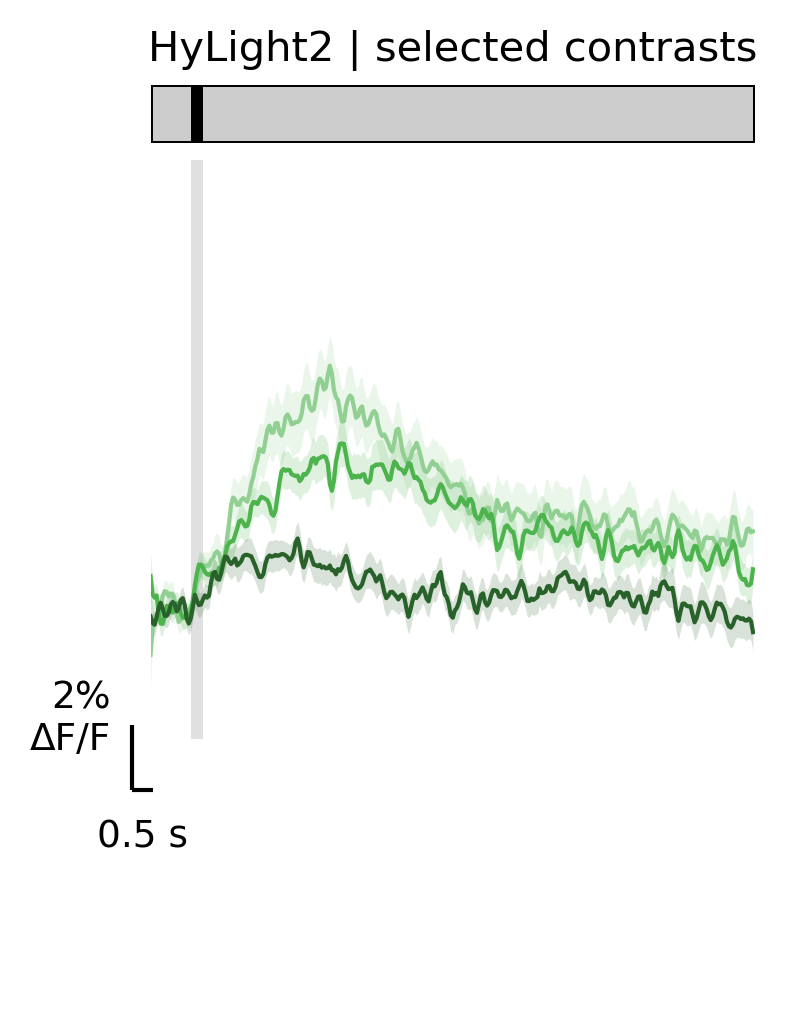

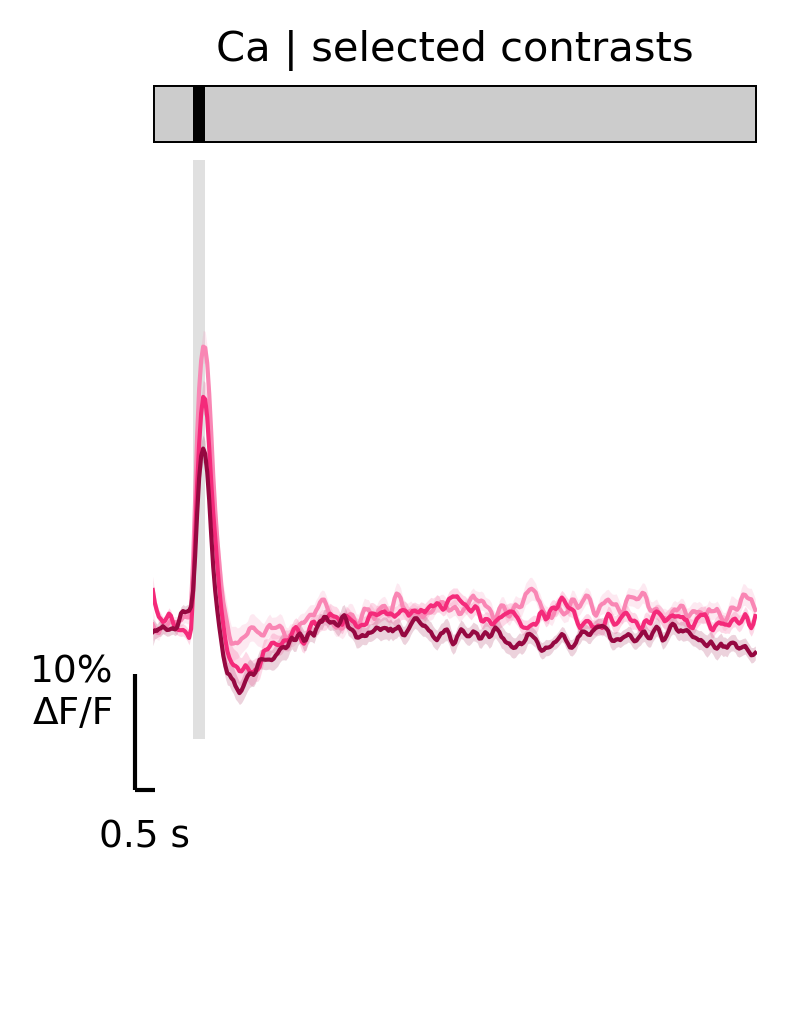

In [17]:
LOW_CONTRASTS = [0.01, 0.2, 0.4]

fig, ax = plot_all_contrasts_overlay_compactstyle_from_csvs(
    records,
    sensor=HYLIGHT_SENSOR,
    stim_type="300msdark",
    contrasts_to_plot=LOW_CONTRASTS,
    contrast_colors=contrast_colors_hylight,
    show_sem=True,
    show_legend=False,
    ylim=(-0.04, 0.14),
    xlim=(0, 15),
    line_width=1,
    figsize=(2.6, 3.6),
    dpi=300,
    df_over_f_scale=0.02,
    time_scale=0.5,
    target_hz=20,
    apply_smoothing=True,
    wid=3,
)

fig, ax = plot_all_contrasts_overlay_compactstyle_from_csvs(
    records,
    sensor=CA_SENSOR,
    stim_type="300msdark",
    contrasts_to_plot=LOW_CONTRASTS,
    contrast_colors=contrast_colors_ca,
    show_sem=True,
    show_legend=False,
    ylim=(-0.1, 0.4),
    xlim=(0, 15),
    line_width=1,
    figsize=(2.6, 3.6),
    dpi=300,
    df_over_f_scale=0.1,
    time_scale=0.5,
    target_hz=20,
    apply_smoothing=True,
    wid=3,
)

## 6. Contrasts above 0.5 (light flash)

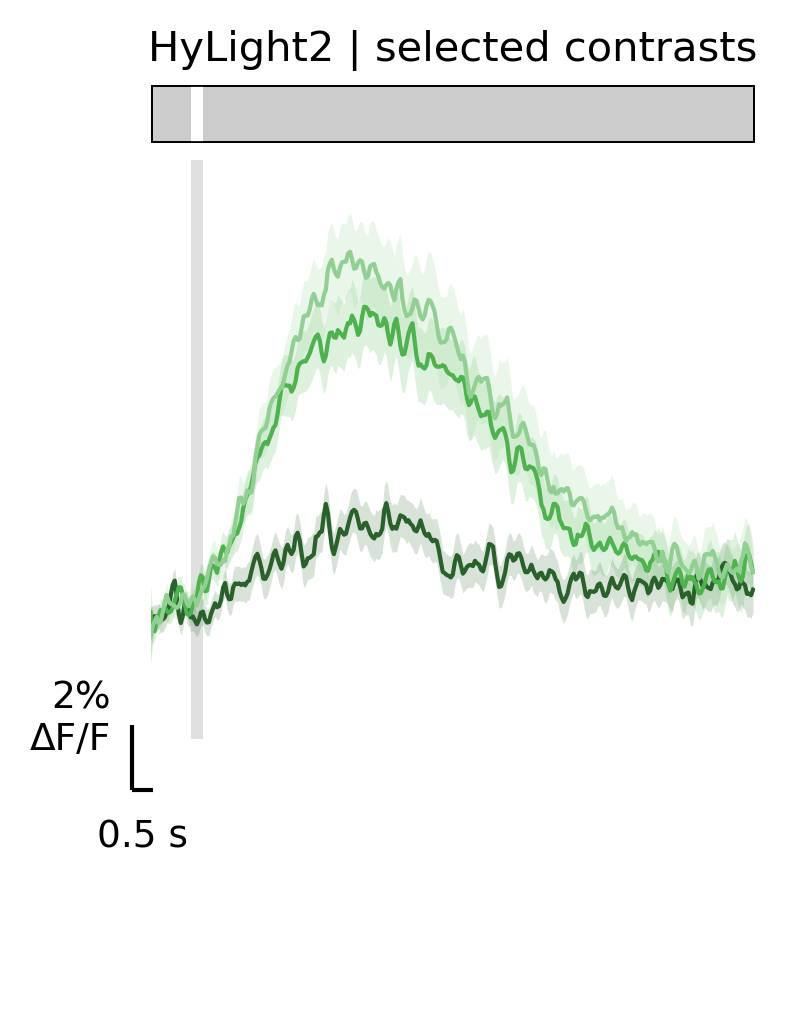

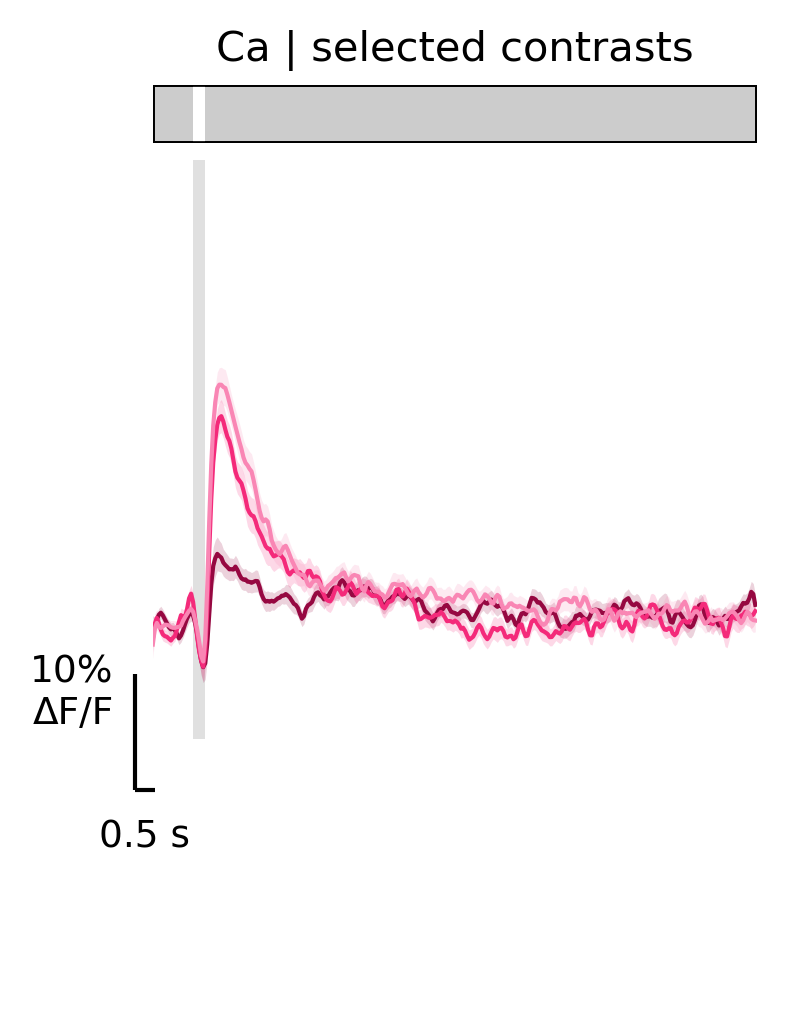

In [18]:
HIGH_CONTRASTS = [0.6, 0.8, 1]

fig, ax = plot_all_contrasts_overlay_compactstyle_from_csvs(
    records,
    sensor=HYLIGHT_SENSOR,
    stim_type="300mslight",
    contrasts_to_plot=HIGH_CONTRASTS,
    contrast_colors=contrast_colors_hylight,
    show_sem=True,
    show_legend=False,
    ylim=(-0.04, 0.14),
    xlim=(0, 15),
    line_width=1,
    figsize=(2.6, 3.6),
    dpi=300,
    df_over_f_scale=0.02,
    time_scale=0.5,
    target_hz=20,
    apply_smoothing=True,
    wid=3,
)

fig, ax = plot_all_contrasts_overlay_compactstyle_from_csvs(
    records,
    sensor=CA_SENSOR,
    stim_type="300mslight",
    contrasts_to_plot=HIGH_CONTRASTS,
    contrast_colors=contrast_colors_ca,
    show_sem=True,
    show_legend=False,
    ylim=(-0.1, 0.4),
    xlim=(0, 15),
    line_width=1,
    figsize=(2.6, 3.6),
    dpi=300,
    df_over_f_scale=0.1,
    time_scale=0.5,
    target_hz=20,
    apply_smoothing=True,
    wid=3,
)